# 04 · Ablation study — which inputs and classes does the model depend on?

The model has only **two input features**, Sentinel-1 **VV** and **VH** backscatter.
To see how much it relies on each, we break the inputs in controlled ways and measure
how much accuracy and mIoU drop compared to the unchanged baseline. A large drop means
the model depends heavily on what was removed.

**Part A – feature ablation (trained model, inputs changed at test time)**

| Experiment | What is removed | What is kept |
|---|---|---|
| VV / VH → median | all information in one channel | the other channel |
| VV / VH permuted | link between that channel and the location (values shuffled between patches) | realistic value distribution |
| Polarisation ratio removed | VH − VV difference (VH rebuilt from VV) | VV brightness and texture |
| Spatial texture removed | patterns inside a patch (each channel set to its patch mean) | average brightness per patch |
| Brightness removed | absolute level (patch mean subtracted) | spatial patterns |
| Gaussian noise σ = 0.1 … 1.0 | progressively more signal | — |

**Part B – class ablation (trained model, outputs restricted)**

A class is removed by forbidding the model to predict it. Pixels of that class are
excluded from scoring, and we see (1) how the remaining classes change and (2) which
class the removed pixels are given instead, which shows which classes the model
treats as similar. Classes are then removed **cumulatively**, weakest first.

**Part D – class merging**

Pairs or groups of classes are merged in both prediction and labels, to see how much
error comes from confusing them and how the model scores with a coarser legend.

**Part C – retraining ablation (optional, slow)**

Changing inputs of an already-trained model shows *dependence*. Training new models
on VV only or VH only shows how much information each channel *carries on its own*.
Off by default (`RUN_RETRAIN = False`) because it trains three models.

All scores are pixel accuracy and mIoU against ESA WorldCover on the held-out test set,
exactly as in notebook 02.

In [23]:
import os, sys, time, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

PROJECT_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(PROJECT_DIR))

from src.model import UNet, load_v5_model
from src.classes import CLASS_NAMES, CLASS_COLORS, CLASS_IDS

NAMES = [CLASS_NAMES[c] for c in CLASS_IDS]
SHORT = ["Tree", "Grass", "Crop", "Built", "Bare", "Water"]

TEST_PATH  = PROJECT_DIR / "patches_v4" / "test_v4.npz"
TRAIN_PATH = PROJECT_DIR / "patches_v5" / "train_v5.npz"
VAL_PATH   = PROJECT_DIR / "patches_v4" / "val_v4.npz"
WEIGHTS    = PROJECT_DIR / "weights" / "best_unet_v5.pt"
OUT_DIR    = PROJECT_DIR / "results" / "ablation"
OUT_DIR.mkdir(parents=True, exist_ok=True)

RUN_RETRAIN = False      # Part C, trains 3 models
RETRAIN_EPOCHS = 10
SEED = 42

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model, checkpoint = load_v5_model(WEIGHTS, device=device)
model.eval()

data = np.load(TEST_PATH)
X_test = data["X"].astype(np.float32)          # normalised VV, VH
y_test = data["y"].astype(np.int64)            # 1-6, 255 = ignore
MEDIANS = np.array(checkpoint["class_medians"], dtype=np.float32)
IQR = np.array(checkpoint["class_iqr"], dtype=np.float32)

print("Device:", device)
print("Test patches:", X_test.shape)
print("Normalisation  median:", MEDIANS, " IQR:", IQR)

Device: cuda
Test patches: (324, 2, 128, 128)
Normalisation  median: [ -9.042964 -15.390633]  IQR: [3.967108  4.4696884]


## Helper functions

In [24]:
def predict_logits(X, batch_size=16):
    out = np.zeros((len(X), 6, X.shape[2], X.shape[3]), dtype=np.float32)
    with torch.no_grad():
        for i in range(0, len(X), batch_size):
            batch = torch.from_numpy(np.ascontiguousarray(X[i:i + batch_size])).to(device)
            out[i:i + batch_size] = model(batch).cpu().numpy()
    return out


def confusion(y, pred):
    # rows = WorldCover class, columns = predicted class (both 1-6)
    valid = (y >= 1) & (y <= 6)
    cm = np.zeros((6, 6), dtype=np.int64)
    np.add.at(cm, (y[valid] - 1, pred[valid] - 1), 1)
    return cm


def scores(cm, classes=range(6)):
    # accuracy and IoU; mIoU is the mean over the given classes
    classes = list(classes)
    tp = np.diag(cm).astype(float)
    actual = cm.sum(axis=1).astype(float)
    predicted = cm.sum(axis=0).astype(float)
    union = actual + predicted - tp
    iou = np.divide(tp, union, out=np.zeros(6), where=union > 0)
    return {
        "accuracy": tp.sum() / max(actual.sum(), 1),
        "mIoU": iou[classes].mean(),
        "iou": iou,
    }


def evaluate(X):
    pred = predict_logits(X).argmax(axis=1) + 1
    return scores(confusion(y_test, pred))


def to_db(x):
    return x * IQR[:, None, None] + MEDIANS[:, None, None]


def from_db(db):
    return (db - MEDIANS[:, None, None]) / IQR[:, None, None]

## Baseline

In [25]:
t0 = time.time()
baseline_logits = predict_logits(X_test)
baseline_pred = baseline_logits.argmax(axis=1) + 1
baseline_cm = confusion(y_test, baseline_pred)
baseline = scores(baseline_cm)

print(f"Baseline  accuracy {baseline['accuracy']:.4f}   mIoU {baseline['mIoU']:.4f}   ({time.time() - t0:.0f} s)")
display(pd.DataFrame({"IoU": baseline["iou"]}, index=NAMES).round(4))

Baseline  accuracy 0.7190   mIoU 0.4734   (0 s)


,IoU
Tree cover,0.5385
Grassland,0.3289
Cropland,0.6564
Built-up,0.6321
Bare/sparse vegetation,0.0000
Permanent water,0.6842


## Part A — Feature ablation

All changes are made on the normalised inputs. In normalised units 0 is the training
median of a channel, and 1 is one IQR (about 4 dB).

In [26]:
rng = np.random.default_rng(SEED)


def replace_with_median(X, ch):
    X = X.copy(); X[:, ch] = 0.0
    return X


def permute_channel(X, ch, seed):
    # swap one channel between patches: values stay realistic but belong to another place
    order = np.random.default_rng(seed).permutation(len(X))
    X = X.copy(); X[:, ch] = X[order, ch]
    return X


def remove_ratio(X):
    # rebuild VH from VV plus the average VH-VV difference, so the ratio carries no information
    db = np.stack([to_db(x) for x in X])
    mean_diff = np.mean(db[:, 1] - db[:, 0])
    db[:, 1] = db[:, 0] + mean_diff
    return np.stack([from_db(d) for d in db]).astype(np.float32)


def remove_texture(X):
    return np.repeat(np.repeat(X.mean(axis=(2, 3), keepdims=True), X.shape[2], axis=2), X.shape[3], axis=3)


def remove_brightness(X):
    return X - X.mean(axis=(2, 3), keepdims=True)


def add_noise(X, sigma, seed):
    noise = np.random.default_rng(seed).normal(0, sigma, X.shape).astype(np.float32)
    return X + noise


experiments = [
    ("VV → median",               "single channel", lambda: replace_with_median(X_test, 0)),
    ("VH → median",               "single channel", lambda: replace_with_median(X_test, 1)),
    ("VV and VH → median",        "single channel", lambda: replace_with_median(X_test, [0, 1])),
    ("VV permuted",               "permutation",    "perm0"),
    ("VH permuted",               "permutation",    "perm1"),
    ("Polarisation ratio removed", "property",      lambda: remove_ratio(X_test)),
    ("Spatial texture removed",   "property",       lambda: remove_texture(X_test)),
    ("Brightness removed",        "property",       lambda: remove_brightness(X_test)),
]
for sigma in [0.1, 0.25, 0.5, 1.0]:
    experiments.append((f"Noise σ={sigma}", "noise", sigma))

rows = []
for name, group, make in experiments:
    t0 = time.time()
    if isinstance(make, str):          # permutation: average over 3 shuffles
        ch = int(make[-1])
        runs = [evaluate(permute_channel(X_test, ch, SEED + k)) for k in range(3)]
    elif isinstance(make, float):      # noise: average over 3 draws
        runs = [evaluate(add_noise(X_test, make, SEED + k)) for k in range(3)]
    else:
        runs = [evaluate(make())]
    acc = np.mean([r["accuracy"] for r in runs])
    miou = np.mean([r["mIoU"] for r in runs])
    iou = np.mean([r["iou"] for r in runs], axis=0)
    rows.append({"experiment": name, "group": group, "accuracy": acc, "mIoU": miou,
                 "Δ accuracy": acc - baseline["accuracy"], "Δ mIoU": miou - baseline["mIoU"],
                 **{s: v for s, v in zip(SHORT, iou)}})
    print(f"{name:28s} acc {acc:.4f}  mIoU {miou:.4f}  Δ mIoU {miou - baseline['mIoU']:+.4f}  ({time.time() - t0:.0f} s)")

baseline_row = {"experiment": "Baseline", "group": "baseline", "accuracy": baseline["accuracy"],
                "mIoU": baseline["mIoU"], "Δ accuracy": 0.0, "Δ mIoU": 0.0,
                **{s: v for s, v in zip(SHORT, baseline["iou"])}}
feature_results = pd.DataFrame([baseline_row] + rows).set_index("experiment")
feature_results.to_csv(OUT_DIR / "feature_ablation.csv")
display(feature_results.round(4))

VV → median                  acc 0.3261  mIoU 0.1071  Δ mIoU -0.3663  (0 s)
VH → median                  acc 0.4466  mIoU 0.1815  Δ mIoU -0.2918  (0 s)
VV and VH → median           acc 0.1760  mIoU 0.0293  Δ mIoU -0.4440  (0 s)
VV permuted                  acc 0.3986  mIoU 0.1571  Δ mIoU -0.3163  (1 s)
VH permuted                  acc 0.4514  mIoU 0.1880  Δ mIoU -0.2854  (1 s)
Polarisation ratio removed   acc 0.5753  mIoU 0.3249  Δ mIoU -0.1485  (0 s)
Spatial texture removed      acc 0.2159  mIoU 0.0494  Δ mIoU -0.4239  (0 s)
Brightness removed           acc 0.6688  mIoU 0.4331  Δ mIoU -0.0403  (0 s)
Noise σ=0.1                  acc 0.7144  mIoU 0.4663  Δ mIoU -0.0071  (1 s)
Noise σ=0.25                 acc 0.6442  mIoU 0.3952  Δ mIoU -0.0781  (1 s)
Noise σ=0.5                  acc 0.4989  mIoU 0.2312  Δ mIoU -0.2421  (1 s)
Noise σ=1.0                  acc 0.4417  mIoU 0.1511  Δ mIoU -0.3223  (1 s)


,group,accuracy,mIoU,Δ accuracy,Δ mIoU,Tree,Grass,Crop,Built,Bare,Water
experiment,,,,,,,,,,,
Baseline,baseline,0.7190,0.4734,0.0000,0.0000,0.5385,0.3289,0.6564,0.6321,0.0,0.6842
VV → median,single channel,0.3261,0.1071,-0.3929,-0.3663,0.1785,0.0140,0.2767,0.1733,0.0,0.0000
VH → median,single channel,0.4466,0.1815,-0.2724,-0.2918,0.2684,0.0888,0.3464,0.3583,0.0,0.0272
VV and VH → median,single channel,0.1760,0.0293,-0.5430,-0.4440,0.0000,0.0000,0.1760,0.0000,0.0,0.0000
VV permuted,permutation,0.3986,0.1571,-0.3204,-0.3163,0.2065,0.0677,0.3201,0.3312,0.0,0.0170
VH permuted,permutation,0.4514,0.1880,-0.2675,-0.2854,0.1938,0.2017,0.2119,0.4868,0.0,0.0338
Polarisation ratio removed,property,0.5753,0.3249,-0.1437,-0.1485,0.4390,0.2824,0.0106,0.5827,0.0,0.6344
Spatial texture removed,property,0.2159,0.0494,-0.5031,-0.4239,0.0971,0.0000,0.1995,0.0000,0.0,0.0000
Brightness removed,property,0.6688,0.4331,-0.0502,-0.0403,0.4766,0.2637,0.5779,0.6028,0.0,0.6775


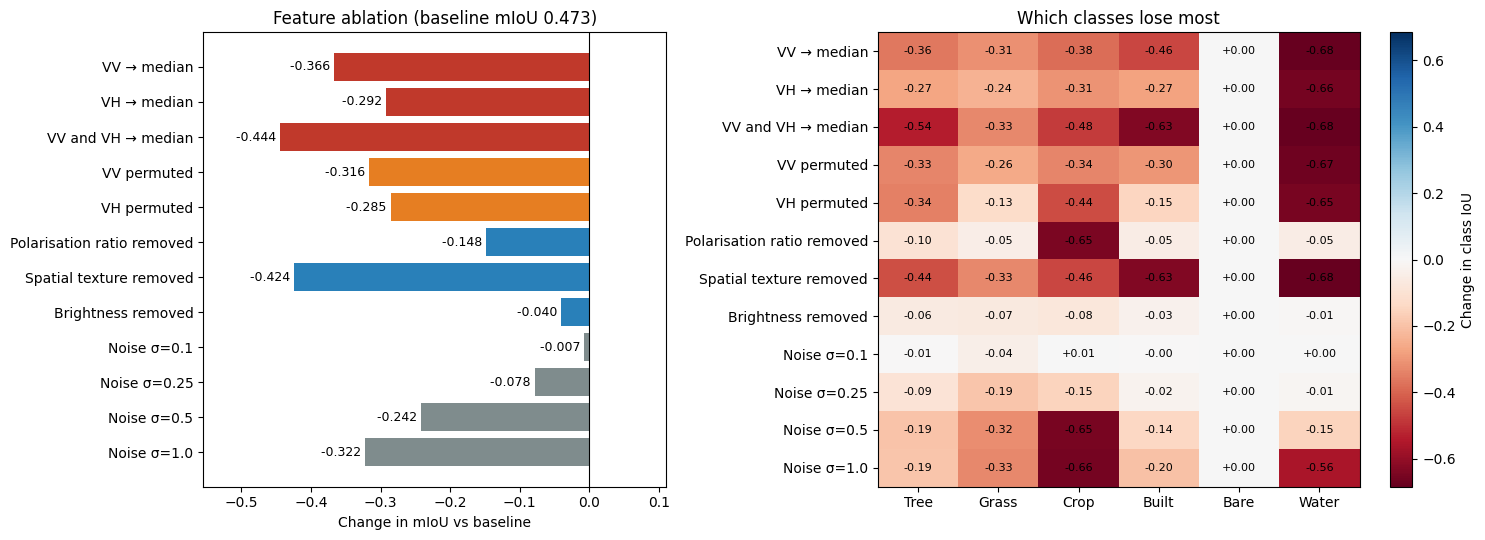

In [27]:
plot = feature_results.drop(index="Baseline")
colors = {"single channel": "#c0392b", "permutation": "#e67e22", "property": "#2980b9", "noise": "#7f8c8d"}

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1, 1.3]})
ax = axes[0]
ax.barh(plot.index, plot["Δ mIoU"], color=[colors[g] for g in plot["group"]])
ax.axvline(0, color="black", lw=0.8)
for i, v in enumerate(plot["Δ mIoU"]):
    ax.text(v, i, f" {v:+.3f} ", va="center", ha="right" if v < 0 else "left", fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("Change in mIoU vs baseline")
ax.set_title(f"Feature ablation (baseline mIoU {baseline['mIoU']:.3f})")
pad = abs(plot["Δ mIoU"]).max() * 0.25
ax.set_xlim(plot["Δ mIoU"].min() - pad, max(plot["Δ mIoU"].max(), 0) + pad)

ax = axes[1]
drop = plot[SHORT].values - baseline["iou"][None, :]
lim = max(abs(drop).max(), 0.05)
im = ax.imshow(drop, cmap="RdBu", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(6)); ax.set_xticklabels(SHORT)
ax.set_yticks(range(len(plot))); ax.set_yticklabels(plot.index)
for r in range(drop.shape[0]):
    for c in range(drop.shape[1]):
        ax.text(c, r, f"{drop[r, c]:+.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="Change in class IoU")
ax.set_title("Which classes lose most")
plt.tight_layout(); plt.savefig(OUT_DIR / "feature_ablation.png", dpi=130); plt.show()

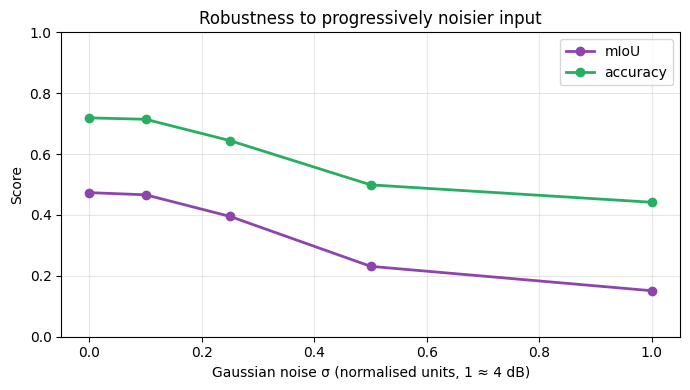

In [28]:
noise = feature_results[feature_results["group"].isin(["baseline", "noise"])]
sigmas = [0.0] + [float(i.split("=")[1]) for i in noise.index[1:]]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sigmas, noise["mIoU"], "o-", label="mIoU", color="#8e44ad", lw=2)
ax.plot(sigmas, noise["accuracy"], "o-", label="accuracy", color="#27ae60", lw=2)
ax.set_xlabel("Gaussian noise σ (normalised units, 1 ≈ 4 dB)")
ax.set_ylabel("Score"); ax.set_ylim(0, 1); ax.grid(alpha=0.3); ax.legend()
ax.set_title("Robustness to progressively noisier input")
plt.tight_layout(); plt.savefig(OUT_DIR / "noise_robustness.png", dpi=130); plt.show()

## Part B — Class ablation

A removed class gets a logit of −∞, so the model must pick one of the remaining classes.
Its pixels are excluded from scoring. mIoU is computed over the remaining classes and
compared to the baseline over **the same classes and the same pixels**, so the numbers
are directly comparable.

In [29]:
def predict_without(removed):
    logits = baseline_logits.copy()
    for c in removed:
        logits[:, c - 1] = -np.inf
    return logits.argmax(axis=1) + 1


def score_without(removed):
    keep = [c - 1 for c in CLASS_IDS if c not in removed]
    y = y_test.copy()
    for c in removed:
        y[y == c] = 255                      # removed class is not scored
    before = scores(confusion(y, baseline_pred), keep)
    after = scores(confusion(y, predict_without(removed)), keep)
    return before, after, keep


rows, where_to = [], {}
for c in CLASS_IDS:
    before, after, keep = score_without([c])
    rows.append({"removed class": CLASS_NAMES[c],
                 "mIoU before": before["mIoU"], "mIoU after": after["mIoU"],
                 "Δ mIoU": after["mIoU"] - before["mIoU"],
                 "Δ accuracy": after["accuracy"] - before["accuracy"],
                 **{SHORT[k]: after["iou"][k] - before["iou"][k] for k in keep}})

    # where do the pixels of the removed class go now?
    mask = y_test == c
    new_pred = predict_without([c])[mask]
    where_to[CLASS_NAMES[c]] = {SHORT[k - 1]: np.mean(new_pred == k) * 100 for k in CLASS_IDS if k != c}

single = pd.DataFrame(rows).set_index("removed class")
single.to_csv(OUT_DIR / "class_ablation_single.csv")
print("Change in the remaining classes when one class is removed (IoU, same pixels):")
display(single.round(4))

destinations = pd.DataFrame(where_to).T.fillna(0)[SHORT]
destinations.to_csv(OUT_DIR / "class_ablation_destinations.csv")
print("Where the pixels of the removed class are predicted instead (% of that class):")
display(destinations.round(1))

Change in the remaining classes when one class is removed (IoU, same pixels):


,mIoU before,mIoU after,Δ mIoU,Δ accuracy,Grass,Crop,Built,Bare,Water,Tree
removed class,,,,,,,,,,
Tree cover,0.5193,0.5552,0.0359,0.0829,0.1252,0.0046,0.0570,0.0000,-0.0073,NaN
Grassland,0.5408,0.5571,0.0162,0.0380,NaN,0.0450,0.0048,0.0000,0.0003,0.0312
Cropland,0.4466,0.4770,0.0304,0.0428,0.1441,NaN,0.0011,0.0000,0.0000,0.0069
Built-up,0.4649,0.5099,0.0450,0.1304,0.0035,0.0013,NaN,0.0014,0.0253,0.1934
Bare/sparse vegetation,0.5685,0.5685,0.0000,0.0001,-0.0000,0.0002,0.0000,NaN,-0.0000,0.0000
Permanent water,0.4324,0.4332,0.0008,0.0024,0.0001,0.0000,0.0012,0.0000,NaN,0.0027


Where the pixels of the removed class are predicted instead (% of that class):


,Tree,Grass,Crop,Built,Bare,Water
Tree cover,0.0,42.1,8.5,48.3,0.0,1.1
Grassland,45.1,0.0,42.9,11.7,0.0,0.3
Cropland,14.5,81.6,0.0,3.8,0.1,0.0
Built-up,92.0,5.0,1.9,0.0,0.5,0.6
Bare/sparse vegetation,14.1,23.2,24.1,35.7,0.0,2.9
Permanent water,28.1,5.5,0.2,65.4,0.8,0.0


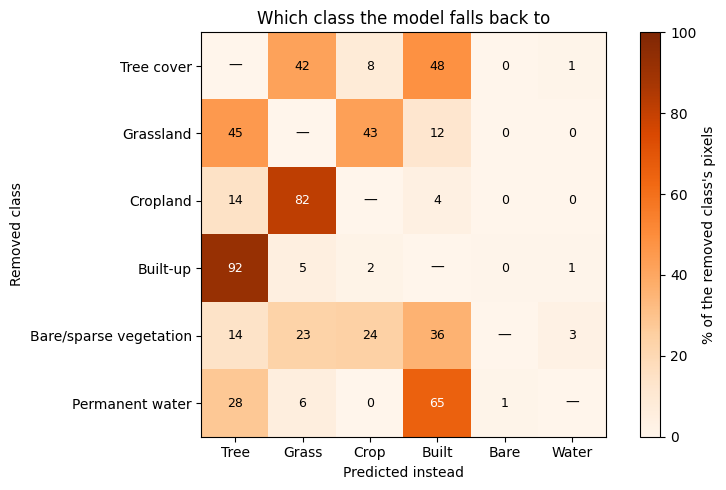

In [30]:
fig, ax = plt.subplots(figsize=(8, 5))
vals = destinations[SHORT].values
im = ax.imshow(vals, cmap="Oranges", vmin=0, vmax=100)
ax.set_xticks(range(6)); ax.set_xticklabels(SHORT)
ax.set_yticks(range(len(destinations))); ax.set_yticklabels(destinations.index)
for r in range(vals.shape[0]):
    for c in range(vals.shape[1]):
        if destinations.index[r].startswith(NAMES[c][:4]):
            ax.text(c, r, "—", ha="center", va="center")
        else:
            ax.text(c, r, f"{vals[r, c]:.0f}", ha="center", va="center",
                    color="white" if vals[r, c] > 60 else "black", fontsize=9)
ax.set_xlabel("Predicted instead"); ax.set_ylabel("Removed class")
fig.colorbar(im, ax=ax, label="% of the removed class's pixels")
ax.set_title("Which class the model falls back to")
plt.tight_layout(); plt.savefig(OUT_DIR / "class_fallback.png", dpi=130); plt.show()

### Progressive removal

Classes are removed one after another, starting with the weakest (lowest baseline IoU),
until two classes remain. The result shows how much of the overall score depends on
the hardest classes.

,classes left,mIoU,accuracy,mIoU if model were unchanged
removed so far,,,,
none,6,0.4734,0.7190,NaN
Bare,5,0.5685,0.7197,0.5685
Bare + Grass,4,0.6971,0.8053,0.6766
Bare + Grass + Tree,3,0.8629,0.9549,0.8012
Bare + Grass + Tree + Built,2,0.9606,0.9927,0.8226


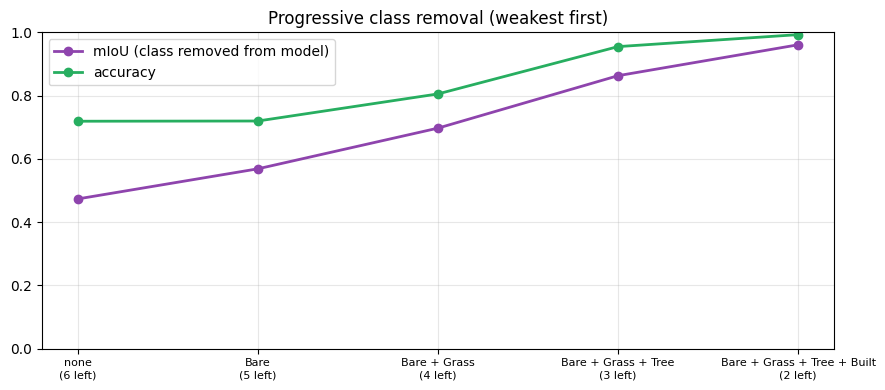

In [31]:
order = [CLASS_IDS[i] for i in np.argsort(baseline["iou"])]
rows, removed = [], []
before, after, keep = score_without([])
rows.append({"removed so far": "none", "classes left": 6, "mIoU": after["mIoU"], "accuracy": after["accuracy"]})
for c in order[:4]:
    removed.append(c)
    before, after, keep = score_without(removed)
    rows.append({"removed so far": " + ".join(SHORT[k - 1] for k in removed),
                 "classes left": len(keep), "mIoU": after["mIoU"], "accuracy": after["accuracy"],
                 "mIoU if model were unchanged": before["mIoU"]})

progressive = pd.DataFrame(rows).set_index("removed so far")
progressive.to_csv(OUT_DIR / "class_ablation_progressive.csv")
display(progressive.round(4))

fig, ax = plt.subplots(figsize=(9, 4))
x = range(len(progressive))
ax.plot(x, progressive["mIoU"], "o-", lw=2, color="#8e44ad", label="mIoU (class removed from model)")
ax.plot(x, progressive["accuracy"], "o-", lw=2, color="#27ae60", label="accuracy")
ax.set_xticks(list(x)); ax.set_xticklabels([f"{n}\n({k} left)" for n, k in zip(progressive.index, progressive["classes left"])], fontsize=8)
ax.set_ylim(0, 1); ax.grid(alpha=0.3); ax.legend()
ax.set_title("Progressive class removal (weakest first)")
plt.tight_layout(); plt.savefig(OUT_DIR / "class_ablation_progressive.png", dpi=130); plt.show()

## Part D — Class merging

Two or more classes are treated as one, both in the predictions and in the WorldCover
labels, and the scores are recalculated. Errors between merged classes stop counting as
errors. This shows how much of the remaining error comes from confusing those classes
with each other, and how the model would score with a coarser legend.

No model is re-run: merging only adds up rows and columns of the baseline confusion matrix.

Keep in mind that merging can only raise accuracy, and that mIoU values with different
numbers of classes are not strictly comparable. The IoU of the merged class and of the
classes that were *not* merged are the more telling numbers.

In [32]:
def merge_confusion(cm, groups):
    # groups: list of lists of class ids (1-6) to merge, other classes stay as they are
    merged_ids = [c for g in groups for c in g]
    new_classes = [list(g) for g in groups] + [[c] for c in CLASS_IDS if c not in merged_ids]
    new_classes.sort(key=lambda g: min(g))

    M = np.zeros((6, len(new_classes)), dtype=np.int64)
    for j, g in enumerate(new_classes):
        for c in g:
            M[c - 1, j] = 1
    names = [" + ".join(SHORT[c - 1] for c in g) for g in new_classes]
    return M.T @ cm @ M, names


def scores_any(cm):
    tp = np.diag(cm).astype(float)
    actual = cm.sum(axis=1).astype(float)
    predicted = cm.sum(axis=0).astype(float)
    union = actual + predicted - tp
    iou = np.divide(tp, union, out=np.zeros(len(tp)), where=union > 0)
    return tp.sum() / actual.sum(), iou.mean(), iou


merge_schemes = [
    ("Baseline (6 classes)",                     []),
    ("Grassland + Cropland",                     [[2, 3]]),
    ("Tree cover + Grassland",                   [[1, 2]]),
    ("Bare/sparse into Grassland",               [[2, 5]]),
    ("Grass + Crop + Bare (low vegetation)",     [[2, 3, 5]]),
    ("Tree cover + Built-up (main confusion)",   [[1, 4]]),
    ("All vegetation (Tree+Grass+Crop+Bare)",    [[1, 2, 3, 5]]),
]

rows, per_class = [], {}
for name, groups in merge_schemes:
    cm_m, names = merge_confusion(baseline_cm, groups)
    acc, miou, iou = scores_any(cm_m)
    merged_names = [n for n in names if "+" in n]
    untouched = [i for i, n in enumerate(names) if "+" not in n]
    rows.append({
        "merge": name,
        "classes": len(names),
        "accuracy": acc,
        "mIoU": miou,
        "Δ accuracy": acc - baseline["accuracy"],
        "Δ mIoU": miou - baseline["mIoU"],
        "IoU of merged class": iou[names.index(merged_names[0])] if merged_names else np.nan,
        "mIoU of untouched classes": iou[untouched].mean() if untouched else np.nan,
    })
    per_class[name] = dict(zip(names, iou))

merge_results = pd.DataFrame(rows).set_index("merge")
merge_results.to_csv(OUT_DIR / "class_merging.csv")
display(merge_results.round(4))

print("IoU per class after merging:")
for name, d in per_class.items():
    print(f"  {name:40s} " + "  ".join(f"{k} {v:.2f}" for k, v in d.items()))

,classes,accuracy,mIoU,Δ accuracy,Δ mIoU,IoU of merged class,mIoU of untouched classes
merge,,,,,,,
Baseline (6 classes),6,0.7190,0.4734,0.0000,0.0000,NaN,0.4734
Grassland + Cropland,5,0.7697,0.5143,0.0508,0.0410,0.7169,0.4637
Tree cover + Grassland,5,0.7729,0.5178,0.0539,0.0444,0.6162,0.4932
Bare/sparse into Grassland,5,0.7192,0.5680,0.0002,0.0946,0.3287,0.6278
Grass + Crop + Bare (low vegetation),4,0.7702,0.6430,0.0513,0.1697,0.7173,0.6183
Tree cover + Built-up (main confusion),5,0.8394,0.5039,0.1204,0.0305,0.8499,0.4174
All vegetation (Tree+Grass+Crop+Bare),3,0.8416,0.7000,0.1226,0.2267,0.7838,0.6582


IoU per class after merging:
  Baseline (6 classes)                     Tree 0.54  Grass 0.33  Crop 0.66  Built 0.63  Bare 0.00  Water 0.68
  Grassland + Cropland                     Tree 0.54  Grass + Crop 0.72  Built 0.63  Bare 0.00  Water 0.68
  Tree cover + Grassland                   Tree + Grass 0.62  Crop 0.66  Built 0.63  Bare 0.00  Water 0.68
  Bare/sparse into Grassland               Tree 0.54  Grass + Bare 0.33  Crop 0.66  Built 0.63  Water 0.68
  Grass + Crop + Bare (low vegetation)     Tree 0.54  Grass + Crop + Bare 0.72  Built 0.63  Water 0.68
  Tree cover + Built-up (main confusion)   Tree + Built 0.85  Grass 0.33  Crop 0.66  Bare 0.00  Water 0.68
  All vegetation (Tree+Grass+Crop+Bare)    Tree + Grass + Crop + Bare 0.78  Built 0.63  Water 0.68


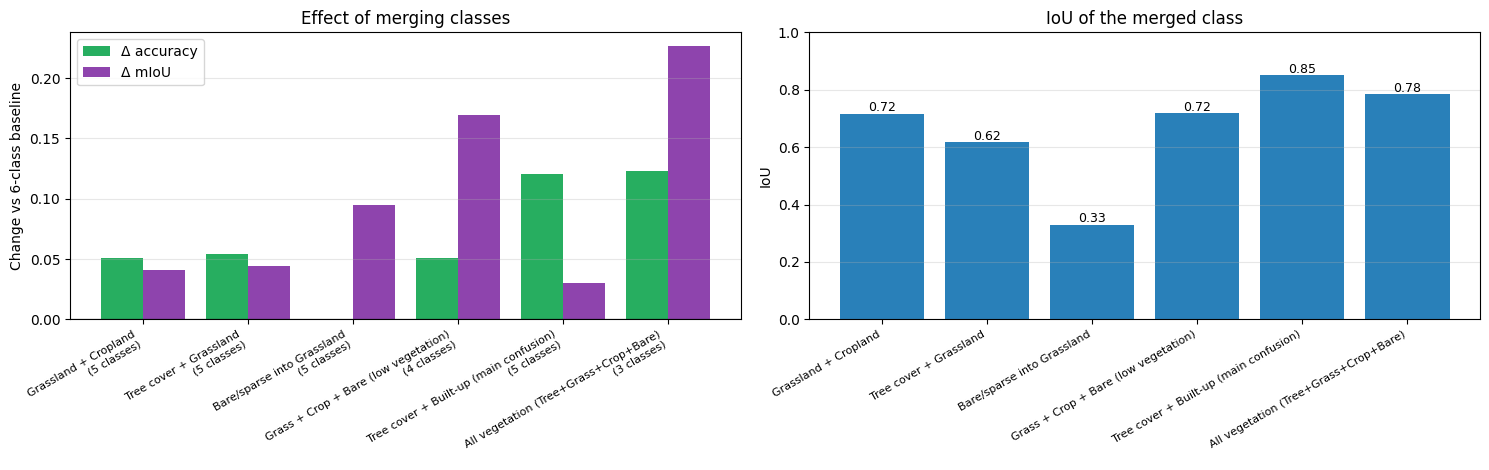

In [33]:
plot = merge_results.drop(index="Baseline (6 classes)")
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

ax = axes[0]
x = np.arange(len(plot))
ax.bar(x - 0.2, plot["Δ accuracy"], 0.4, label="Δ accuracy", color="#27ae60")
ax.bar(x + 0.2, plot["Δ mIoU"], 0.4, label="Δ mIoU", color="#8e44ad")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x); ax.set_xticklabels([f"{n}\n({k} classes)" for n, k in zip(plot.index, plot["classes"])],
                                     rotation=30, ha="right", fontsize=8)
ax.set_ylabel("Change vs 6-class baseline"); ax.legend(); ax.grid(axis="y", alpha=0.3)
ax.set_title("Effect of merging classes")

ax = axes[1]
ax.bar(x, plot["IoU of merged class"], color="#2980b9")
for i, v in enumerate(plot["IoU of merged class"]):
    ax.text(i, v + 0.01, f"{v:.2f}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(plot.index, rotation=30, ha="right", fontsize=8)
ax.set_ylim(0, 1); ax.set_ylabel("IoU"); ax.grid(axis="y", alpha=0.3)
ax.set_title("IoU of the merged class")

plt.tight_layout(); plt.savefig(OUT_DIR / "class_merging.png", dpi=130); plt.show()

## Part C — Retraining ablation (optional)

Three models with the same settings and the same number of epochs: both channels,
VV only, VH only. Each is scored with its best validation checkpoint on the test set.
The 2-channel model here is retrained with the shorter budget so the comparison is fair;
it will not match the 30-epoch baseline exactly.

In [34]:
if RUN_RETRAIN:
    from torch.utils.data import TensorDataset, DataLoader, WeightedRandomSampler

    def load_split(path):
        d = np.load(path)
        y = d["y"].astype(np.int64)
        return d["X"].astype(np.float32), np.where(y == 255, 255, y - 1)

    X_tr, y_tr = load_split(TRAIN_PATH)
    X_va, y_va = load_split(VAL_PATH)
    y_te0 = np.where(y_test == 255, 255, y_test - 1)
    class_weights = torch.tensor([0.48, 0.48, 0.48, 0.48, 2.398, 1.684], device=device)

    rare = ((y_tr == 4).sum(axis=(1, 2)) >= 100) | ((y_tr == 5).sum(axis=(1, 2)) >= 100)
    sample_weights = torch.as_tensor(np.where(rare, 2.0, 1.0), dtype=torch.double)

    def run_eval(net, X, y, channels):
        net.eval(); cm = np.zeros((6, 6), dtype=np.int64)
        with torch.no_grad():
            for i in range(0, len(X), 16):
                xb = torch.from_numpy(np.ascontiguousarray(X[i:i + 16][:, channels])).to(device)
                pred = net(xb).argmax(1).cpu().numpy()
                yb = y[i:i + 16]; v = yb != 255
                np.add.at(cm, (yb[v], pred[v]), 1)
        return scores(cm)

    retrain_rows = []
    for name, channels in [("VV + VH", [0, 1]), ("VV only", [0]), ("VH only", [1])]:
        torch.manual_seed(SEED)
        net = UNet(in_channels=len(channels), num_classes=6, base_channels=16).to(device)
        opt = torch.optim.AdamW(net.parameters(), lr=1e-3, weight_decay=1e-4)
        loss_fn = nn.CrossEntropyLoss(weight=class_weights, ignore_index=255)
        sampler = WeightedRandomSampler(sample_weights, len(sample_weights), replacement=True,
                                        generator=torch.Generator().manual_seed(SEED))
        loader = DataLoader(TensorDataset(torch.from_numpy(X_tr[:, channels]), torch.from_numpy(y_tr)),
                            batch_size=4, sampler=sampler, num_workers=2)
        best, best_state = -1, None
        for epoch in range(1, RETRAIN_EPOCHS + 1):
            net.train(); t0 = time.time()
            for xb, yb in loader:
                opt.zero_grad()
                loss = loss_fn(net(xb.to(device)), yb.to(device))
                loss.backward(); opt.step()
            val = run_eval(net, X_va, y_va, channels)
            if val["mIoU"] > best:
                best = val["mIoU"]
                best_state = {k: v.detach().clone() for k, v in net.state_dict().items()}
            print(f"{name:8s} epoch {epoch:2d}  val mIoU {val['mIoU']:.4f}  ({time.time() - t0:.0f} s)")
        net.load_state_dict(best_state)
        test = run_eval(net, X_test, y_te0, channels)
        retrain_rows.append({"model": name, "best val mIoU": best, "test accuracy": test["accuracy"],
                             "test mIoU": test["mIoU"], **{s: v for s, v in zip(SHORT, test["iou"])}})

    retrain = pd.DataFrame(retrain_rows).set_index("model")
    retrain.to_csv(OUT_DIR / "retrain_ablation.csv")
    display(retrain.round(4))
else:
    print("Skipped. Set RUN_RETRAIN = True in the first cell to train the VV-only and VH-only models.")

Skipped. Set RUN_RETRAIN = True in the first cell to train the VV-only and VH-only models.


## Summary

In [35]:
ranking = feature_results.drop(index="Baseline")
ranking = ranking[ranking["group"] != "noise"].sort_values("Δ mIoU")
print(f"Baseline: accuracy {baseline['accuracy']:.4f}, mIoU {baseline['mIoU']:.4f}\n")
print("Feature ablations, largest mIoU drop first:")
for name, r in ranking.iterrows():
    print(f"  {name:28s} Δ mIoU {r['Δ mIoU']:+.4f}   Δ accuracy {r['Δ accuracy']:+.4f}")

print("\nClass ablation, effect of removing one class on the others (Δ mIoU, same pixels):")
for name, r in single.sort_values("Δ mIoU", ascending=False).iterrows():
    target = destinations.loc[name].idxmax()
    print(f"  without {name:24s} Δ mIoU {r['Δ mIoU']:+.4f}   its pixels mostly become {target} "
          f"({destinations.loc[name].max():.0f} %)")

print("\nClass merging (Δ vs 6-class baseline):")
for name, r in merge_results.drop(index="Baseline (6 classes)").iterrows():
    print(f"  {name:40s} accuracy {r['accuracy']:.4f} ({r['Δ accuracy']:+.4f})   mIoU {r['mIoU']:.4f} ({r['Δ mIoU']:+.4f})   "
          f"merged-class IoU {r['IoU of merged class']:.3f}")

summary = {"baseline": {"accuracy": baseline["accuracy"], "mIoU": baseline["mIoU"]},
           "feature_ablation": feature_results[["accuracy", "mIoU", "Δ mIoU"]].round(4).to_dict(orient="index"),
           "class_ablation_single": single[["Δ mIoU"]].round(4).to_dict(orient="index"),
           "class_merging": merge_results[["classes", "accuracy", "mIoU", "IoU of merged class"]].round(4).to_dict(orient="index")}
json.dump(summary, open(OUT_DIR / "summary.json", "w"), indent=2, default=float)
print("\nAll tables and figures saved in", OUT_DIR)

Baseline: accuracy 0.7190, mIoU 0.4734

Feature ablations, largest mIoU drop first:
  VV and VH → median           Δ mIoU -0.4440   Δ accuracy -0.5430
  Spatial texture removed      Δ mIoU -0.4239   Δ accuracy -0.5031
  VV → median                  Δ mIoU -0.3663   Δ accuracy -0.3929
  VV permuted                  Δ mIoU -0.3163   Δ accuracy -0.3204
  VH → median                  Δ mIoU -0.2918   Δ accuracy -0.2724
  VH permuted                  Δ mIoU -0.2854   Δ accuracy -0.2675
  Polarisation ratio removed   Δ mIoU -0.1485   Δ accuracy -0.1437
  Brightness removed           Δ mIoU -0.0403   Δ accuracy -0.0502

Class ablation, effect of removing one class on the others (Δ mIoU, same pixels):
  without Built-up                 Δ mIoU +0.0450   its pixels mostly become Tree (92 %)
  without Tree cover               Δ mIoU +0.0359   its pixels mostly become Built (48 %)
  without Cropland                 Δ mIoU +0.0304   its pixels mostly become Grass (82 %)
  without Grassland         